# Conformal prediction: onzekerheid met een garantie

**Topic 5 — PXL · wanneer mag je model zelf beslissen?**

---

## Het probleem

Je model geeft een antwoord. Eén antwoord. "Dit is een 4."

Maar je wil iets anders weten: **mag ik hierop vertrouwen?** En als het model er 9% van de tijd
naast zit, wil je weten *bij welke 9%*. Een model dat bij elke voorspelling even stellig klinkt,
kan je dat niet vertellen.

De softmax-uitvoer lijkt te helpen — "97% zeker" — maar dat is een getal dat het model zelf
verzint. Er zit geen belofte achter. Niemand garandeert je dat de gevallen waarin het model
90% zegt, ook echt in 90% van de keren kloppen.

## Wat conformal prediction doet

In plaats van één antwoord geeft het model een **verzameling** antwoorden, met een belofte
die je aan je opdrachtgever kunt uitleggen:

> *"In 95% van de gevallen zit het juiste antwoord in deze verzameling."*

En dat is geen schatting maar een garantie, die je achteraf gewoon kunt natellen. Verder:

- Het werkt op **elk** model. Random forest, neuraal netwerk, iets van een leverancier waar je
  de binnenkant niet van kent — maakt niet uit.
- Je hoeft het model **niet opnieuw te trainen**.
- Het kost je ongeveer **vijf regels code**.

De prijs staat in dat woord *verzameling*. Soms krijg je één antwoord terug, soms drie. En
juist dát blijkt het nuttigste signaal van allemaal: het model geeft eindelijk toe wanneer het
twijfelt.

## Wat we gaan doen

1. Een model trainen dat bewust niet perfect is
2. Zien waarom "97% zeker" geen garantie is
3. Conformal prediction toepassen — in vier stappen
4. De garantie natellen
5. Er een werkstroom van maken: wat automatiseren we, en wat gaat naar een mens?
6. Kijken naar de gevallen waar het model twijfelt

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("numpy ", np.__version__)
print("pandas", pd.__version__)

numpy  2.5.3
pandas 3.0.5


## 1. De data en een model

We gebruiken handgeschreven cijfers (MNIST). Handig om twee redenen: je kunt ze **zien**, en
sommige cijfers lijken nu eenmaal op elkaar. Een slordige 4 is een 9, en een 3 is een 5 met
een bochtje. Dat is precies het soort twijfel dat we zichtbaar willen maken.

We knippen de data in **drie** stukken, en dat derde stuk is het hele punt van deze les:

| deel | waarvoor |
|---|---|
| **train** | het model leren |
| **kalibratie** | uitzoeken hoe vaak het model er normaal naast zit |
| **test** | controleren of onze belofte klopt |

Het kalibratiedeel is nieuw. Het model mag het nooit gezien hebben tijdens het trainen.

20,000 cijfers van 28x28 pixels
klassen: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


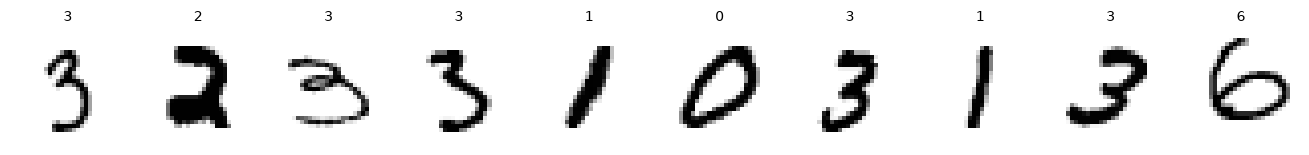

In [2]:
bestand = Path("data/cijfers.npz")
if not bestand.exists():
    raise FileNotFoundError(
        "Data niet gevonden. Draai eerst eenmalig:  .venv/bin/python haal_data.py")

d = np.load(bestand)
X = d["X"].astype("float32") / 255.0      # pixels naar 0-1
y = d["y"].astype(int)

print(f"{len(X):,} cijfers van 28x28 pixels")
print(f"klassen: {sorted(set(y))}")

fig, assen = plt.subplots(1, 10, figsize=(12, 1.5))
for ax, k in zip(assen, np.random.default_rng(0).choice(len(X), 10, replace=False)):
    ax.imshow(X[k].reshape(28, 28), cmap="gray_r"); ax.set_title(y[k], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

In [3]:
# Bewust een klein trainingsdeel: we willen een model dat het redelijk doet
# maar zeker niet perfect. Een model dat nooit fouten maakt, heeft geen
# onzekerheid om over te praten.
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, train_size=2000, random_state=RANDOM_STATE, stratify=y)

X_kalib, X_test, y_kalib, y_test = train_test_split(
    X_rest, y_rest, train_size=4000, random_state=RANDOM_STATE, stratify=y_rest)

print(f"train      : {len(X_train):>6,}")
print(f"kalibratie : {len(X_kalib):>6,}")
print(f"test       : {len(X_test):>6,}")

train      :  2,000
kalibratie :  4,000
test       : 14,000


In [4]:
model = MLPClassifier(hidden_layer_sizes=(64,), max_iter=60, random_state=RANDOM_STATE)
model.fit(X_train, y_train)

accuratesse = model.score(X_test, y_test)
print(f"test-accuracy: {accuratesse:.1%}")
print(f"Dus ongeveer {1 - accuratesse:.0%} van de cijfers gaat mis.")
print("De vraag van deze notebook: bij WELKE?")

test-accuracy: 90.8%
Dus ongeveer 9% van de cijfers gaat mis.
De vraag van deze notebook: bij WELKE?


## 2. Waarom "97% zeker" geen garantie is

Laten we eerst kijken wat de softmax-uitvoer waard is. We zetten de voorspellingen op een rij
per zekerheidsniveau, en tellen hoe vaak het model in elke groep gelijk had.

In [5]:
kansen = model.predict_proba(X_test)
zekerheid = kansen.max(axis=1)
voorspelling = kansen.argmax(axis=1)
klopt = voorspelling == y_test

# Let op de ondergrens. Bij tien klassen kan de hoogste kans nooit onder de 10%
# liggen: de tien kansen tellen op tot 1, dus de grootste is minstens 1/10.
# Er bestaat hier ook geen binaire drempel van 50% - het model kiest altijd de
# hoogste van tien kansen, ook als die maar 0.21 is.
ondergrens = 1 / kansen.shape[1]

rijen = []
for laag, hoog in [(ondergrens, 0.5), (0.5, 0.7), (0.7, 0.9), (0.9, 0.99), (0.99, 1.01)]:
    groep = (zekerheid >= laag) & (zekerheid < hoog)
    if groep.sum() < 20:
        continue
    rijen.append({
        "model zegt": f"{laag:.0%} – {hoog:.0%}",
        "aantal": int(groep.sum()),
        "klopt echt": f"{klopt[groep].mean():.1%}",
    })
display(pd.DataFrame(rijen).set_index("model zegt"))

print(f"De laagste topkans in de hele testset is {zekerheid.min():.2f}.")
print(f"Bij {(zekerheid < 0.5).mean():.1%} van de cijfers blijft de beste gok onder de 50%,")
print(f"en daar klopt er {(klopt[zekerheid < 0.5]).mean():.0%}. Die worden gewoon voorspeld -")
print("een model met tien klassen kent geen 'ja/nee'-grens bij 0.5.")
print()
print("Dit model valt nog mee: de percentages liggen in de buurt van wat het belooft.")
print("Maar let op wat er ontbreekt: nergens staat een GARANTIE. Dat dit vandaag klopt,")
print("zegt niets over morgen, en het zegt al helemaal niets over één losse voorspelling.")
print()
print("En het grootste probleem is iets anders:")
print("het model geeft ALTIJD precies één antwoord, ook als het eigenlijk geen idee heeft.")

,aantal,klopt echt
model zegt,,
10% – 50%,341,40.2%
50% – 70%,897,55.1%
70% – 90%,1582,76.2%
90% – 99%,3364,92.7%
99% – 101%,7816,99.3%


De laagste topkans in de hele testset is 0.21.
Bij 2.4% van de cijfers blijft de beste gok onder de 50%,
en daar klopt er 40%. Die worden gewoon voorspeld -
een model met tien klassen kent geen 'ja/nee'-grens bij 0.5.

Dit model valt nog mee: de percentages liggen in de buurt van wat het belooft.
Maar let op wat er ontbreekt: nergens staat een GARANTIE. Dat dit vandaag klopt,
zegt niets over morgen, en het zegt al helemaal niets over één losse voorspelling.

En het grootste probleem is iets anders:
het model geeft ALTIJD precies één antwoord, ook als het eigenlijk geen idee heeft.


---

## 3. Conformal prediction in vier stappen

Hier is het hele idee, zonder formules:

> **Kijk op je kalibratiedata hoe ver het model er normaal naast zit. Gebruik die
> gebruikelijke misser als marge voor nieuwe voorspellingen.**

Dat is het. Vier stappen:

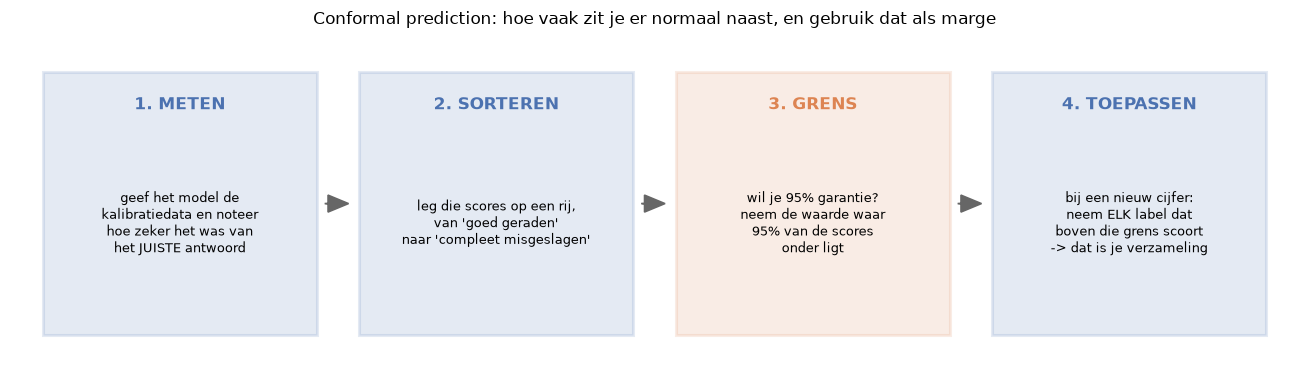

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.6))

stappen = [
    ("1. METEN",      "geef het model de\nkalibratiedata en noteer\nhoe zeker het was van\nhet JUISTE antwoord"),
    ("2. SORTEREN",   "leg die scores op een rij,\nvan 'goed geraden'\nnaar 'compleet misgeslagen'"),
    ("3. GRENS",      "wil je 95% garantie?\nneem de waarde waar\n95% van de scores\nonder ligt"),
    ("4. TOEPASSEN",  "bij een nieuw cijfer:\nneem ELK label dat\nboven die grens scoort\n-> dat is je verzameling"),
]

for k, (titel, tekst) in enumerate(stappen):
    kleur = "#DD8452" if k == 2 else "#4C72B0"
    ax.add_patch(plt.Rectangle((k * 3, 0), 2.6, 2.0, facecolor=kleur, alpha=0.15,
                               edgecolor=kleur, lw=2))
    ax.text(k * 3 + 1.3, 1.72, titel, ha="center", fontsize=11, fontweight="bold", color=kleur)
    ax.text(k * 3 + 1.3, 0.85, tekst, ha="center", fontsize=8.5, va="center")
    if k < 3:
        ax.arrow(k * 3 + 2.68, 1.0, 0.22, 0, head_width=0.13, color="0.4",
                 length_includes_head=True)

ax.set_xlim(-0.3, 11.9); ax.set_ylim(-0.3, 2.3); ax.axis("off")
ax.set_title("Conformal prediction: hoe vaak zit je er normaal naast, en gebruik dat als marge",
             fontsize=11)
plt.tight_layout(); plt.show()

### Stap 1 en 2: meten hoe zeker het model was van het juiste antwoord

Voor elk cijfer in de kalibratieset kijken we: **welke kans gaf het model aan het antwoord dat
echt klopte?** Was dat 0.99, dan zat het er goed in. Was dat 0.02, dan had het model geen idee.

Om er een "hoe fout zat ik"-score van te maken, rekenen we met `1 - die kans`. Hoog is slecht.

Voorbeeld, de eerste vijf kalibratiecijfers:
  echt een 4 | model gaf daar  78.3% aan -> score 0.217
  echt een 0 | model gaf daar  95.7% aan -> score 0.043
  echt een 4 | model gaf daar  99.9% aan -> score 0.001
  echt een 1 | model gaf daar 100.0% aan -> score 0.000
  echt een 7 | model gaf daar 100.0% aan -> score 0.000


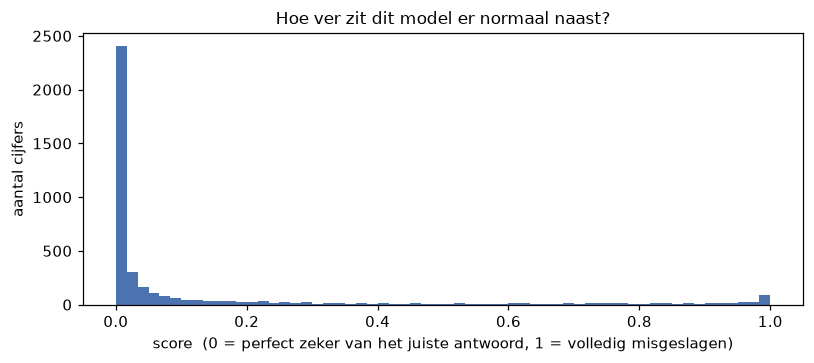

Bij 78% van de kalibratiecijfers zat het model er bovenop.
Bij 4% had het er volledig naast.


In [7]:
kansen_kalib = model.predict_proba(X_kalib)

# De kans die het model gaf aan het ECHTE label van elk kalibratiecijfer.
kans_juiste_label = kansen_kalib[np.arange(len(y_kalib)), y_kalib]
score = 1 - kans_juiste_label          # hoog = het model zat er ver naast

print("Voorbeeld, de eerste vijf kalibratiecijfers:")
for k in range(5):
    print(f"  echt een {y_kalib[k]} | model gaf daar {kans_juiste_label[k]:6.1%} aan "
          f"-> score {score[k]:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(score, bins=60, color="#4C72B0")
ax.set_xlabel("score  (0 = perfect zeker van het juiste antwoord, 1 = volledig misgeslagen)")
ax.set_ylabel("aantal cijfers")
ax.set_title("Hoe ver zit dit model er normaal naast?", fontsize=11)
plt.tight_layout(); plt.show()

print(f"Bij {np.mean(score < 0.1):.0%} van de kalibratiecijfers zat het model er bovenop.")
print(f"Bij {np.mean(score > 0.9):.0%} had het er volledig naast.")

### Stap 3: de grens kiezen

Nu de enige keuze die jij moet maken: **hoeveel fouten accepteer je?**

Wil je dat het juiste antwoord in 95% van de gevallen in je verzameling zit, dan zoek je de
waarde waar 95% van de kalibratiescores onder ligt. Alles wat slechter scoort dan die grens,
valt buiten de boot.

*(Het `(n+1)` in de code hieronder is een kleine correctie voor het feit dat je maar een
eindige kalibratieset hebt. Zonder die correctie kom je net iets te laag uit.)*

In [8]:
def bepaal_grens(scores, alpha):
    # alpha = hoeveel fouten je accepteert. alpha=0.05 -> 95% garantie.
    n = len(scores)

    # Een garantie kan niet scherper zijn dan je kalibratieset toelaat. Met n punten
    # is de strengste zinnige grens "alles behalve de slechtste", en dat komt neer
    # op minstens 1/alpha - 1 punten. Met 50 punten is 99% dus onmogelijk: je hebt
    # simpelweg geen enkele score die zeldzaam genoeg is om die grens te trekken.
    minimaal = int(np.ceil(1 / alpha)) - 1
    if n < minimaal:
        raise ValueError(
            f"{n} kalibratiepunten is te weinig voor een garantie van {1 - alpha:.0%}. "
            f"Je hebt er minstens {minimaal} nodig. Kies een lagere garantie, "
            f"of maak de kalibratieset groter."
        )

    niveau = np.ceil((n + 1) * (1 - alpha)) / n
    return np.quantile(scores, niveau, method="higher")


ALPHA = 0.05                            # verander dit gerust: 0.10, 0.01, ...
grens = bepaal_grens(score, ALPHA)

print(f"gekozen garantie : {1 - ALPHA:.0%}")
print(f"grens            : {grens:.4f}")
print()
print(f"Vertaald: een label komt in de verzameling als het model er minstens")
print(f"{1 - grens:.1%} kans aan geeft.")

# En wat als je kalibratieset te klein is voor de garantie die je vraagt?
try:
    bepaal_grens(score[:50], 0.01)
except ValueError as fout:
    print()
    print("Probeer je 99% garantie te halen uit 50 kalibratiepunten:")
    print(f"  {fout}")

gekozen garantie : 95%
grens            : 0.8525

Vertaald: een label komt in de verzameling als het model er minstens
14.8% kans aan geeft.

Probeer je 99% garantie te halen uit 50 kalibratiepunten:
  50 kalibratiepunten is te weinig voor een garantie van 99%. Je hebt er minstens 99 nodig. Kies een lagere garantie, of maak de kalibratieset groter.


### Stap 4: verzamelingen maken

Voor een nieuw cijfer nemen we **elk label** waarvan de score onder de grens blijft. Geen
`argmax`, geen "de hoogste wint" — gewoon iedereen die door de keuring komt.

In [9]:
def maak_verzamelingen(kansen, grens):
    # Per rij een boolean per label: doet hij mee, ja of nee?
    return (1 - kansen) <= grens


kansen_test = model.predict_proba(X_test)
verzamelingen = maak_verzamelingen(kansen_test, grens)

# Even kijken hoe dat er voor een paar cijfers uitziet.
for k in [0, 1, 2, 3, 4]:
    labels_in_set = np.where(verzamelingen[k])[0]
    print(f"  echt een {y_test[k]}  ->  verzameling {set(labels_in_set)}")

  echt een 9  ->  verzameling {np.int64(9), np.int64(4)}
  echt een 9  ->  verzameling {np.int64(0)}
  echt een 0  ->  verzameling {np.int64(0)}
  echt een 6  ->  verzameling {np.int64(6)}
  echt een 3  ->  verzameling {np.int64(3)}


---

## 4. Klopt de garantie?

Nu de controle. We beloofden dat het juiste antwoord in 95% van de gevallen in de verzameling
zou zitten. Laten we het natellen — op testdata die nergens in dit proces gebruikt is.

In [10]:
zit_erin = verzamelingen[np.arange(len(y_test)), y_test]
dekking = zit_erin.mean()

print(f"beloofd  : {1 - ALPHA:.1%}")
print(f"gemeten  : {dekking:.1%}   ({zit_erin.sum():,} van de {len(y_test):,} testcijfers)")

beloofd  : 95.0%
gemeten  : 94.8%   (13,273 van de 14,000 testcijfers)


In [11]:
# En bij andere garantieniveaus?
rijen = []
for a in [0.20, 0.10, 0.05, 0.01]:
    g = bepaal_grens(score, a)
    v = maak_verzamelingen(kansen_test, g)
    groottes = v.sum(axis=1)
    rijen.append({
        "beloofd": f"{1 - a:.0%}",
        "gemeten": f"{v[np.arange(len(y_test)), y_test].mean():.1%}",
        "gem. aantal labels": round(groottes.mean(), 2),
        "1 label": f"{np.mean(groottes == 1):.0%}",
        "meer dan 1": f"{np.mean(groottes > 1):.0%}",
        "leeg": f"{np.mean(groottes == 0):.0%}",
    })
tabel = pd.DataFrame(rijen).set_index("beloofd")
display(tabel)

,gemeten,gem. aantal labels,1 label,meer dan 1,leeg
beloofd,,,,,
80%,80.3%,0.83,83%,0%,17%
90%,90.2%,0.98,98%,0%,2%
95%,94.8%,1.15,87%,13%,0%
99%,99.3%,2.50,39%,61%,0%


**Kijk naar de eerste twee kolommen.** Beloofd en gemeten lopen bij elk niveau gelijk op, en
we hebben daar niets voor hoeven doen: geen aannames over de data, geen hertraining, geen
gepruts aan het model.

**Kijk daarna naar de laatste drie.** Dáár zit de prijs. Wil je van 90% naar 99% garantie,
dan moet het model vaker meerdere opties openhouden. Zekerheid koop je met vaagheid.

> **Die kolom "leeg" is geen fout.** Een lege verzameling betekent: *geen enkel label komt
> door de keuring*. Dit cijfer lijkt op niets wat het model kent. In de praktijk is dat een
> nuttig signaal — zo'n invoer wil je sowieso apart leggen.

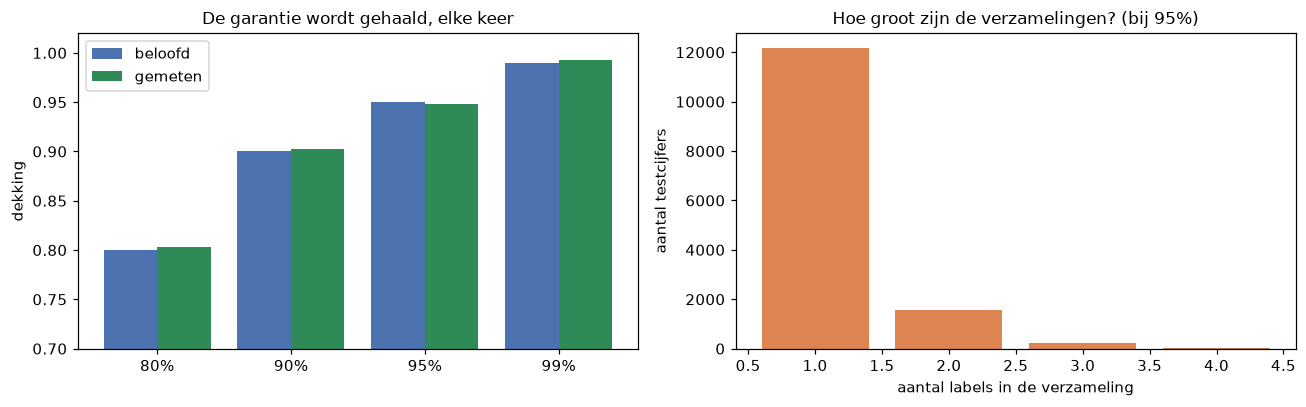

In [12]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.8))

niveaus = [0.20, 0.10, 0.05, 0.01]
beloofd = [1 - x for x in niveaus]
gemeten = []
for alph in niveaus:
    g = bepaal_grens(score, alph)
    v = maak_verzamelingen(kansen_test, g)
    gemeten.append(v[np.arange(len(y_test)), y_test].mean())

x = np.arange(len(niveaus))
a.bar(x - 0.2, beloofd, 0.4, label="beloofd", color="#4C72B0")
a.bar(x + 0.2, gemeten, 0.4, label="gemeten", color="#2E8B57")
a.set_xticks(x); a.set_xticklabels([f"{b:.0%}" for b in beloofd])
a.set_ylim(0.7, 1.02); a.set_ylabel("dekking"); a.legend()
a.set_title("De garantie wordt gehaald, elke keer", fontsize=11)

groottes = verzamelingen.sum(axis=1)
telling = Counter(groottes)
b.bar(list(telling.keys()), list(telling.values()), color="#DD8452")
b.set_xlabel("aantal labels in de verzameling"); b.set_ylabel("aantal testcijfers")
b.set_title(f"Hoe groot zijn de verzamelingen? (bij {1 - ALPHA:.0%})", fontsize=11)

plt.tight_layout(); plt.show()

### "Maar 94,8% is toch minder dan 95%?"

Goed opgemerkt, en dit is precies de plek waar de meeste mensen de garantie verkeerd begrijpen.

De belofte geldt **gemiddeld over kalibratiesets**, niet voor elke losse set. Had je toevallig
4000 andere cijfers gekalibreerd, dan was de grens iets anders uitgevallen en de dekking ook.
Soms zit je er een half procent boven, soms eronder.

Laten we dat niet aannemen maar meten: hetzelfde model, veertig verschillende kalibratiesets.

doel                : 95.0%
gemiddelde dekking  : 94.99%   <- dit is wat de garantie belooft
laagste tot hoogste : 93.84% tot 96.02%
onder het doel      : 23 van de 40 keer


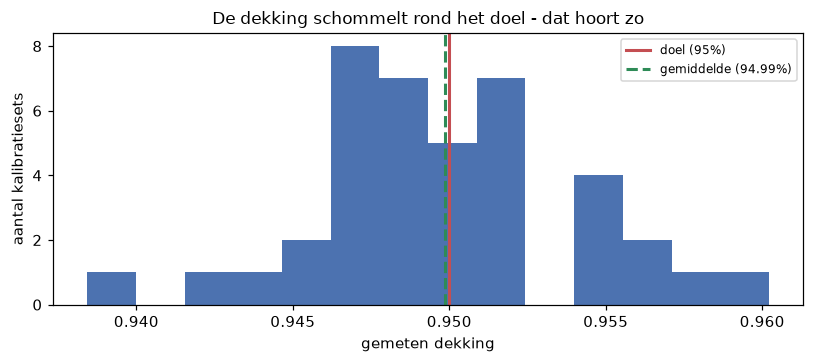

In [13]:
# Het model blijft hetzelfde; alleen de SPLIT tussen kalibratie en test varieert.
kansen_rest = model.predict_proba(X_rest)

dekkingen = []
for seed in range(40):
    k_idx, t_idx = train_test_split(
        np.arange(len(y_rest)), train_size=4000, random_state=seed, stratify=y_rest)
    g = bepaal_grens(1 - kansen_rest[k_idx, y_rest[k_idx]], ALPHA)
    v = (1 - kansen_rest[t_idx]) <= g
    dekkingen.append(v[np.arange(len(t_idx)), y_rest[t_idx]].mean())

dekkingen = np.array(dekkingen)

print(f"doel                : {1 - ALPHA:.1%}")
print(f"gemiddelde dekking  : {dekkingen.mean():.2%}   <- dit is wat de garantie belooft")
print(f"laagste tot hoogste : {dekkingen.min():.2%} tot {dekkingen.max():.2%}")
print(f"onder het doel      : {(dekkingen < 1 - ALPHA).sum()} van de 40 keer")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(dekkingen, bins=14, color="#4C72B0")
ax.axvline(1 - ALPHA, color="#C44E52", lw=2, label=f"doel ({1 - ALPHA:.0%})")
ax.axvline(dekkingen.mean(), color="#2E8B57", lw=2, ls="--",
           label=f"gemiddelde ({dekkingen.mean():.2%})")
ax.set_xlabel("gemeten dekking"); ax.set_ylabel("aantal kalibratiesets")
ax.set_title("De dekking schommelt rond het doel - dat hoort zo", fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Het gemiddelde landt op de belofte, en ongeveer de helft van de runs zit eronder. Dat is geen
gebrek maar de definitie: **marginale dekking.**

Wil je minder schommeling, dan is er één knop: een **grotere kalibratieset**. Wil je een
garantie die voor élke losse set geldt, dan heb je een ander soort conformal prediction nodig
(*training-conditional*), en die is conservatiever — je betaalt hem in grotere verzamelingen.

---

## 5. En nu het praktische deel: een werkstroom

Tot hier is het een statistische truc. Nu maken we er iets van waar een organisatie wat aan
heeft.

De verzamelinggrootte vertelt je namelijk precies wat je wil weten:

| verzameling | betekenis | wat je ermee doet |
|---|---|---|
| **1 label** | het model twijfelt niet | automatisch afhandelen |
| **2 of meer** | het model twijfelt | naar een mens |
| **leeg** | dit lijkt nergens op | naar een mens, met voorrang |

Laten we uitrekenen wat dat oplevert.

In [14]:
groottes = verzamelingen.sum(axis=1)
voorspelling_test = kansen_test.argmax(axis=1)
klopt_test = voorspelling_test == y_test

zeker = groottes == 1                      # automatiseren
twijfel = ~zeker                           # naar een mens

print(f"AUTOMATISCH        : {zeker.mean():.1%} van alle cijfers")
print(f"  daarvan klopt    : {klopt_test[zeker].mean():.2%}")
print()
print(f"NAAR EEN MENS      : {twijfel.mean():.1%} van alle cijfers")
print(f"  daarvan zou het model {(~klopt_test[twijfel]).mean():.1%} fout hebben gedaan")
print()
totaal_fout = (~klopt_test).sum()
gevangen = (~klopt_test & twijfel).sum()
print(f"Van de {totaal_fout:,} fouten die het model zou maken,")
print(f"belanden er {gevangen:,} ({gevangen / totaal_fout:.0%}) vanzelf op de mens-stapel.")

AUTOMATISCH        : 86.9% van alle cijfers
  daarvan klopt    : 95.71%

NAAR EEN MENS      : 13.1% van alle cijfers
  daarvan zou het model 41.6% fout hebben gedaan

Van de 1,285 fouten die het model zou maken,
belanden er 763 (59%) vanzelf op de mens-stapel.


Lees dat laatste getal nog eens. **Door 13% van het werk apart te leggen, vang je 59% van alle
fouten af.** Dat is geen toeval: de verzameling wordt juist groot bij de gevallen waar het
model het moeilijk heeft.

En je kunt aan die knop draaien. Wil je dat er minder naar een mens gaat, zet `ALPHA` hoger;
wil je meer fouten afvangen, zet hem lager. De tabel hieronder is het gesprek dat je met je
opdrachtgever voert.

In [15]:
rijen = []
for a in [0.20, 0.10, 0.05, 0.02, 0.01]:
    g = bepaal_grens(score, a)
    v = maak_verzamelingen(kansen_test, g)
    gr = v.sum(axis=1)
    auto = gr == 1
    fout_in_mens = (~klopt_test & ~auto).sum()
    rijen.append({
        "garantie": f"{1 - a:.0%}",
        "automatisch": f"{auto.mean():.0%}",
        "correct als automatisch": f"{klopt_test[auto].mean():.1%}" if auto.sum() else "-",
        "naar een mens": f"{(~auto).mean():.0%}",
        "fouten afgevangen": f"{fout_in_mens / totaal_fout:.0%}",
    })
display(pd.DataFrame(rijen).set_index("garantie"))

print("Hoger in de tabel: minder handwerk, meer fouten die doorglippen.")
print("Lager in de tabel: meer handwerk, bijna niets glipt er nog door.")
print("Welke rij de juiste is, hangt af van wat een fout kost. Dat is geen technische vraag.")

,automatisch,correct als automatisch,naar een mens,fouten afgevangen
garantie,,,,
80%,83%,96.8%,17%,71%
90%,98%,91.9%,2%,14%
95%,87%,95.7%,13%,59%
98%,63%,98.9%,37%,93%
99%,39%,99.6%,61%,98%


Hoger in de tabel: minder handwerk, meer fouten die doorglippen.
Lager in de tabel: meer handwerk, bijna niets glipt er nog door.
Welke rij de juiste is, hangt af van wat een fout kost. Dat is geen technische vraag.


---

## 6. Waar twijfelt het model over?

Het mooiste van deze aanpak: je kunt de twijfel gewoon **bekijken**. Hieronder de cijfers waar
het model meerdere opties openhield — met de verzameling erbij.

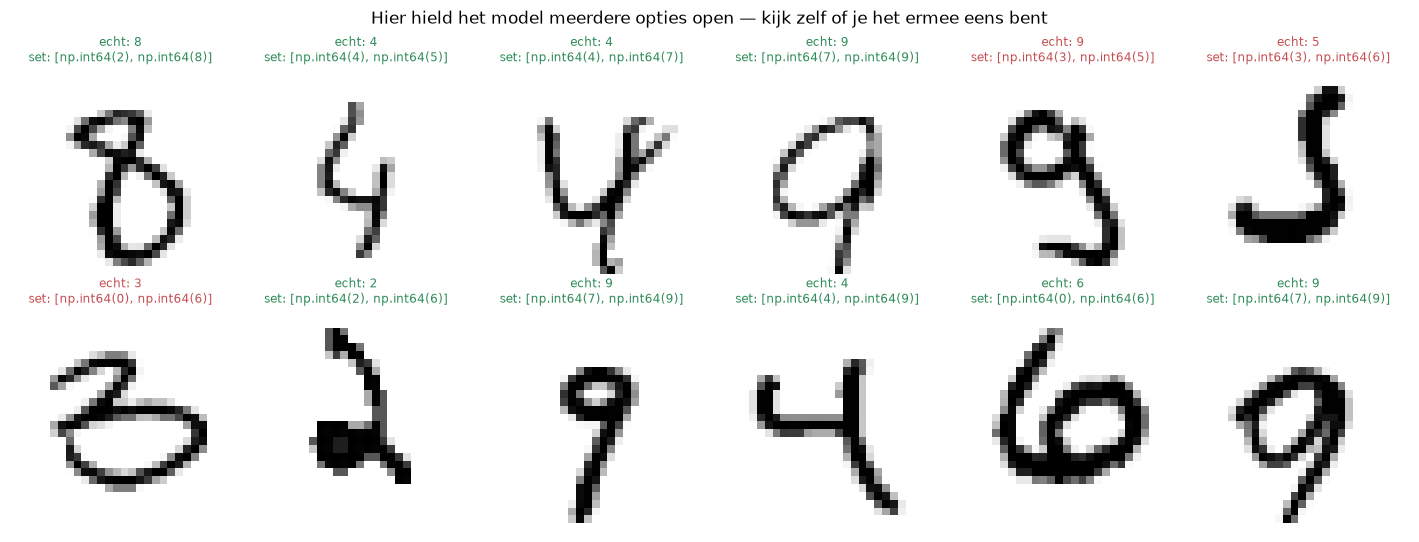

In [16]:
onzeker = np.where(groottes > 1)[0]
keuze = np.random.default_rng(3).choice(onzeker, 12, replace=False)

fig, assen = plt.subplots(2, 6, figsize=(13, 5))
for ax, k in zip(assen.ravel(), keuze):
    labels_in_set = sorted(np.where(verzamelingen[k])[0])
    goed = y_test[k] in labels_in_set
    ax.imshow(X_test[k].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"echt: {y_test[k]}\nset: {labels_in_set}", fontsize=8,
                 color="#2E8B57" if goed else "#C44E52")
    ax.axis("off")
fig.suptitle("Hier hield het model meerdere opties open — kijk zelf of je het ermee eens bent",
             fontsize=11)
plt.tight_layout(); plt.show()

In [17]:
# Welke labels komen samen in één verzameling terecht?
paren = Counter()
for rij in verzamelingen[groottes == 2]:
    a, b = np.where(rij)[0]
    paren[(int(a), int(b))] += 1

print("De verwarringsparen die het vaakst samen voorkomen:\n")
for (a, b), aantal in paren.most_common(6):
    print(f"   {{{a}, {b}}}  —  {aantal}x")
print()
print("Precies de paren die een mens ook door elkaar haalt. Het model heeft dus")
print("niet zomaar onzekerheid, maar ZINNIGE onzekerheid.")

De verwarringsparen die het vaakst samen voorkomen:

   {4, 9}  —  190x
   {7, 9}  —  179x
   {3, 5}  —  162x
   {2, 8}  —  105x
   {2, 3}  —  85x
   {3, 8}  —  65x

Precies de paren die een mens ook door elkaar haalt. Het model heeft dus
niet zomaar onzekerheid, maar ZINNIGE onzekerheid.


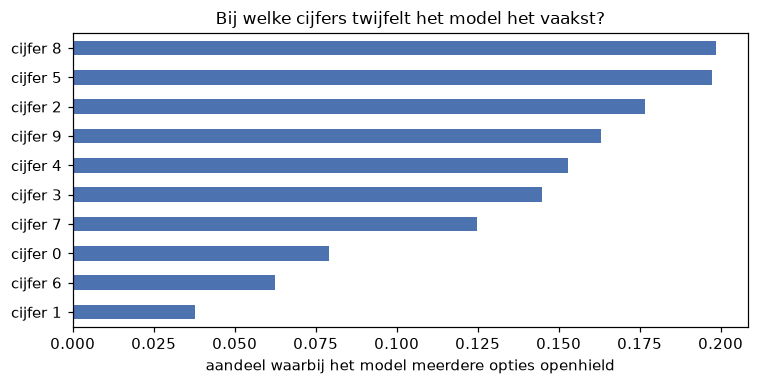

,aandeel met twijfel,aantal in test
cijfer 8,0.199,1355
cijfer 5,0.197,1222
cijfer 2,0.177,1382
cijfer 9,0.163,1374
cijfer 4,0.153,1374
cijfer 3,0.145,1437
cijfer 7,0.125,1457
cijfer 0,0.079,1415
cijfer 6,0.062,1362
cijfer 1,0.038,1622


In [18]:
# Welke cijfers zijn het lastigst?
per_cijfer = pd.DataFrame({
    "aandeel met twijfel": [np.mean(groottes[y_test == c] > 1) for c in range(10)],
    "aantal in test": [int((y_test == c).sum()) for c in range(10)],
}, index=[f"cijfer {c}" for c in range(10)]).sort_values("aandeel met twijfel", ascending=False)

fig, ax = plt.subplots(figsize=(7, 3.6))
per_cijfer["aandeel met twijfel"][::-1].plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("aandeel waarbij het model meerdere opties openhield")
ax.set_title("Bij welke cijfers twijfelt het model het vaakst?", fontsize=11)
plt.tight_layout(); plt.show()

display(per_cijfer.round(3))

---

## Samengevat

Wat je hebt gedaan, in vijf regels code:

```python
score  = 1 - kansen_kalib[np.arange(len(y_kalib)), y_kalib]   # hoe fout zat ik normaal?
grens  = bepaal_grens(score, alpha)                            # waar ligt mijn marge?
sets   = (1 - kansen_test) <= grens                            # wie komt door de keuring?
```

En wat je ervoor terugkreeg:

- **Een garantie die je kunt natellen** — beloofd 95%, gemeten 94,8%.
- **Een model dat toegeeft wanneer het twijfelt**, in plaats van altijd één antwoord te roepen.
- **Een werkstroom**: 87% automatisch afhandelen, 13% naar een mens, en daarmee 59% van alle
  fouten afvangen.
- **Geen hertraining, geen aannames over je data, en het werkt op elk model.**

> Dezelfde vier stappen werken voor regressie. Daar is de score `|voorspeld - echt|` op je
> kalibratiedata, en het resultaat is geen verzameling maar een interval: *"de prijs van dit
> huis ligt tussen 240.000 en 310.000, en in 95% van de gevallen klopt dat."*